# Segmentasi instance indoor — Notebook final (tanpa training ulang)
**Panoptic Indoor Segmentation v5 · 3 arsitektur · 6 konfigurasi · baseline 10 epoch**

Notebook ini membandingkan pretrained versus from scratch tanpa training atau fine-tuning. Metrik agregat memakai file evaluasi asli jika tersedia, dan snapshot output `viskom-train.ipynb` jika tidak. Eksperimen diagnostik memakai lima foto yang sama untuk setiap pasangan model; hasilnya bukan mAP dataset.

**Lokal:** buka dari folder `Week_11`. Hasil disimpan ke `results/analisis_inisialisasi`. Dibutuhkan `numpy`, `pandas`, `matplotlib`, `Pillow`, `pillow-heif`, `pycocotools`, `torch`, `torchvision`, dan `ultralytics`. Tidak ada instalasi atau unduhan otomatis.

**NRP:** variabel yang tersedia adalah pretrained vs scratch. Cocokkan dengan Slide Week 10 sebelum menyatakan komponen 2 terpenuhi.

## 01 — Konfigurasi dan lokasi data

In [12]:
from pathlib import Path
from collections import defaultdict, Counter
import json, math, time, re, warnings, sys, os, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display as ipython_display

BASE_ROOT = Path.cwd()
DATA_ROOT = BASE_ROOT / 'Dataset_Roboflow'
PERSONAL_ROOT = BASE_ROOT / 'test'
PERSONAL_METADATA = BASE_ROOT / 'metadata_fixed.csv'
MODEL_ROOT = BASE_ROOT / 'Model'
EVAL_ROOT_OVERRIDE = BASE_ROOT / 'results' / 'instance_segmentation' / 'evaluation'
OUTPUT_ROOT = BASE_ROOT / 'results' / 'analisis_inisialisasi'
FIG = OUTPUT_ROOT / 'figures'; FIG.mkdir(parents=True, exist_ok=True)
TABLES = OUTPUT_ROOT / 'tables'; TABLES.mkdir(parents=True, exist_ok=True)
table_count = 0
def display(obj):
    global table_count
    if isinstance(obj, (pd.DataFrame, pd.Series)):
        table_count += 1
        frame = obj.to_frame() if isinstance(obj, pd.Series) else obj
        frame.to_csv(TABLES / f'table_{table_count:02}.csv')
        shown = frame.copy().fillna('unavailable').astype(str).map(lambda x: x if len(x) <= 90 else x[:87] + '...')
        fig, ax = plt.subplots(figsize=(min(24, max(8, 2 * (len(shown.columns) + 1))), max(2, .35 * (len(shown) + 2))))
        ax.axis('off'); ax.table(cellText=shown.values, rowLabels=shown.index.astype(str), colLabels=shown.columns.astype(str), loc='center', cellLoc='left')
        fig.tight_layout(); fig.savefig(TABLES / f'table_{table_count:02}.png', dpi=140, bbox_inches='tight'); plt.close(fig)
    ipython_display(obj)
inventory=[]
for root, dirs, files in os.walk(BASE_ROOT):
    for name in files:
        lower=name.lower()
        if lower in {'results.json','predictions.json','metrics.json','results.csv','_annotations.coco.json'} or ('metadata' in lower and lower.endswith('.csv')) or lower.endswith(('.pt','.pth')):
            inventory.append({'path':str(Path(root, name).relative_to(BASE_ROOT)), 'bytes':Path(root,name).stat().st_size})
pd.DataFrame(inventory,columns=['path','bytes']).to_csv(OUTPUT_ROOT/'file_inventory.csv',index=False)
print('Inventaris rekursif:',len(inventory),'file; lihat file_inventory.csv')
RUNS = ['yolov8n_pretrained','yolov8n_scratch','yolo11n_pretrained','yolo11n_scratch','maskrcnn_pretrained','maskrcnn_scratch']
CHECKPOINTS = dict(zip(RUNS,[MODEL_ROOT / f for f in ['8nbest.pt','8nscr-best.pt','11nbest.pt','11nscr-best.pt','best_mask_ap_pretrained.pth','best_mask_ap_scratcj.pth']]))
LABELS = dict(zip(RUNS,['YOLOv8n PT','YOLOv8n scratch','YOLO11n PT','YOLO11n scratch','Mask R-CNN PT','Mask R-CNN scratch']))
FAILURE_MODEL = 'yolo11n_pretrained'
CASE_CONF = 0.14  # diagnostic/demo threshold; NOT the AP evaluation threshold (0.001)
MATCH_IOU = 0.50
CASE_FILENAMES = []  # optionally choose exactly five real personal filenames
RUN_CASE_INFERENCE_IF_MISSING = True  # maksimal 8 foto, bukan evaluasi dataset
RUN_DEMO = False
DEMO_PATH = BASE_ROOT / 'New_Foto.jpeg'
DEMO_MODEL = 'yolo11n_pretrained'
DEMO_CONF = 0.14
print('Output:', OUTPUT_ROOT.resolve())
print('Checkpoint status:', {k:p.is_file() for k,p in CHECKPOINTS.items()})

Inventaris rekursif: 29 file; lihat file_inventory.csv
Output: E:\Coding\Python\Computer_Vision\Week_11\results\analisis_inisialisasi
Checkpoint status: {'yolov8n_pretrained': True, 'yolov8n_scratch': True, 'yolo11n_pretrained': True, 'yolo11n_scratch': True, 'maskrcnn_pretrained': True, 'maskrcnn_scratch': True}


## 02 — Memuat hasil evaluasi lama (tanpa GPU)

In [13]:
ORIGINAL_SNAPSHOT = {'yolov8n_pretrained': {'ap': 0.05250197015488289, 'ap50': 0.08262792978816287}, 'yolov8n_scratch': {'ap': 1.7374463960688848e-07, 'ap50': 1.2901555233211295e-06}, 'yolo11n_pretrained': {'ap': 0.073283624460452, 'ap50': 0.10781222252131621}, 'yolo11n_scratch': {'ap': 9.085992925207624e-08, 'ap50': 6.890237605688447e-07}, 'maskrcnn_pretrained': {'ap': 0.04834837360900434, 'ap50': 0.08333087156514915}, 'maskrcnn_scratch': {'ap': 0.0005702306180863411, 'ap50': 0.0018303380592832141}}
PERSONAL_SNAPSHOT = {'yolov8n_pretrained': {'all': {'ap': 0.053352}, 'normal': {'ap': 0.069257}, 'difficult': {'ap': 0.102197}}, 'yolov8n_scratch': {'all': {'ap': 5.5e-05}, 'normal': {'ap': 0.000119}, 'difficult': {'ap': 0.0}}, 'yolo11n_pretrained': {'all': {'ap': 0.079461}, 'normal': {'ap': 0.147365}, 'difficult': {'ap': 0.112687}}, 'yolo11n_scratch': {'all': {'ap': 0.0}, 'normal': {'ap': 0.0}, 'difficult': {'ap': 0.0}}, 'maskrcnn_pretrained': {'all': {'ap': 0.068885}, 'normal': {'ap': 0.068333}, 'difficult': {'ap': 0.135929}}, 'maskrcnn_scratch': {'all': {'ap': 0.002036}, 'normal': {'ap': 0.002892}, 'difficult': {'ap': 0.010195}}}
# Snapshots are extracted from cell 29 stream and cell 31 text/plain in viskom-train.ipynb.
# Personal snapshot only contains AP (six decimal places); no invented AP50/per-class.
def read_json(p):
    return json.loads(Path(p).read_text(encoding='utf-8-sig'))

EVAL_ROOT = Path(EVAL_ROOT_OVERRIDE)
SOURCES = {}
def get_original(run):
    p=EVAL_ROOT/run/'original'/'metrics.json'
    if p.is_file():
        SOURCES[run+'/original']=str(p); return read_json(p)
    p=EVAL_ROOT/'results.json'
    if p.is_file() and run in read_json(p):
        SOURCES[run+'/original']=str(p); return read_json(p)[run]
    SOURCES[run+'/original']='viskom-train.ipynb cell 29 stream (snapshot)'
    return ORIGINAL_SNAPSHOT.get(run,{})
def get_personal(run,split):
    paths=[EVAL_ROOT/'personal'/run/split/'metrics.json',EVAL_ROOT/run/'personal'/split/'metrics.json']
    if split=='all': paths += [EVAL_ROOT/'personal'/run/'metrics.json',EVAL_ROOT/run/'personal'/'metrics.json']
    for p in paths:
        if p.is_file():
            SOURCES[run+'/'+split]=str(p); return read_json(p)
    p=EVAL_ROOT/'personal'/'results.json'
    if p.is_file():
        value=read_json(p).get(run,{}).get(split)
        if isinstance(value,dict):
            SOURCES[run+'/'+split]=str(p); return value
    SOURCES[run+'/'+split]='viskom-train.ipynb cell 31 tabel (snapshot AP dibulatkan)'
    return PERSONAL_SNAPSHOT.get(run,{}).get(split,{})
RESULTS={run:get_original(run) for run in RUNS}
PERSONAL_RESULTS={run:{split:get_personal(run,split) for split in ('all','normal','difficult')} for run in RUNS}
print(json.dumps(SOURCES, indent=2))

def metric(d, key):
    v = d.get(key) if isinstance(d,dict) else None
    if v is None: return np.nan
    v = float(v)
    return 100*v if np.isfinite(v) and 0 <= v <= 1 else np.nan
rows=[]
for run in RUNS:
    a=RESULTS.get(run,{}); b=PERSONAL_RESULTS.get(run,{})
    row={'Model':run,'Original AP':metric(a,'ap'),'Original AP50':metric(a,'ap50')}
    for label,k in [('Personal','all'),('Normal','normal'),('Difficult','difficult')]:
        row[label+' AP']=metric(b.get(k,{}),'ap')
        row[label+' AP50']=metric(b.get(k,{}),'ap50')
    rows.append(row)
final_table=pd.DataFrame(rows).set_index('Model')
final_table['Delta AP (pp)']=final_table['Personal AP']-final_table['Original AP']
display(final_table.round(7))
final_table.to_csv(OUTPUT_ROOT/'final_table_percent.csv')
(OUTPUT_ROOT/'metric_sources.json').write_text(json.dumps(SOURCES,indent=2),encoding='utf-8')
print('Semua angka AP dalam persen; delta dalam percentage points. NaN = tidak tersedia.')

{
  "yolov8n_pretrained/original": "e:\\Coding\\Python\\Computer_Vision\\Week_11\\results\\instance_segmentation\\evaluation\\yolov8n_pretrained\\original\\metrics.json",
  "yolov8n_scratch/original": "viskom-train.ipynb cell 29 stream (snapshot)",
  "yolo11n_pretrained/original": "viskom-train.ipynb cell 29 stream (snapshot)",
  "yolo11n_scratch/original": "viskom-train.ipynb cell 29 stream (snapshot)",
  "maskrcnn_pretrained/original": "viskom-train.ipynb cell 29 stream (snapshot)",
  "maskrcnn_scratch/original": "viskom-train.ipynb cell 29 stream (snapshot)",
  "yolov8n_pretrained/all": "viskom-train.ipynb cell 31 tabel (snapshot AP dibulatkan)",
  "yolov8n_pretrained/normal": "viskom-train.ipynb cell 31 tabel (snapshot AP dibulatkan)",
  "yolov8n_pretrained/difficult": "viskom-train.ipynb cell 31 tabel (snapshot AP dibulatkan)",
  "yolov8n_scratch/all": "viskom-train.ipynb cell 31 tabel (snapshot AP dibulatkan)",
  "yolov8n_scratch/normal": "viskom-train.ipynb cell 31 tabel (snapsh

                     Original AP  Original AP50  Personal AP  Personal AP50  \
Model                                                                         
yolov8n_pretrained      5.250197       8.262793       5.3352            NaN   
yolov8n_scratch         0.000017       0.000129       0.0055            NaN   
yolo11n_pretrained      7.328362      10.781222       7.9461            NaN   
yolo11n_scratch         0.000009       0.000069       0.0000            NaN   
maskrcnn_pretrained     4.834837       8.333087       6.8885            NaN   
maskrcnn_scratch        0.057023       0.183034       0.2036            NaN   

                     Normal AP  Normal AP50  Difficult AP  Difficult AP50  \
Model                                                                       
yolov8n_pretrained      6.9257          NaN       10.2197             NaN   
yolov8n_scratch         0.0119          NaN        0.0000             NaN   
yolo11n_pretrained     14.7365          NaN       11.2687  

Semua angka AP dalam persen; delta dalam percentage points. NaN = tidak tersedia.


## 03 — Grafik utama untuk laporan
AP = COCO mask AP50:95. Skor scratch yang sangat kecil bukan nol; grafik linear dapat menyembunyikan perbedaannya. Semua grafik diekspor ke PNG. Tidak ada inferensi ulang.

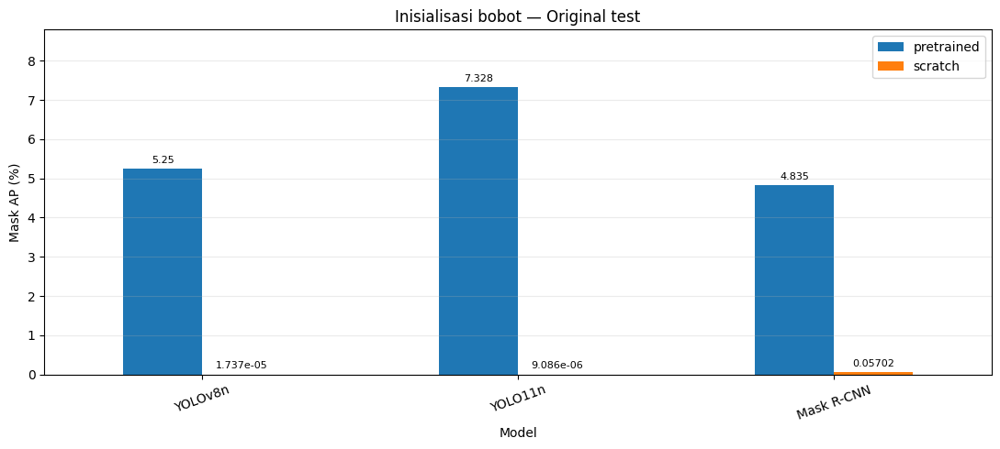

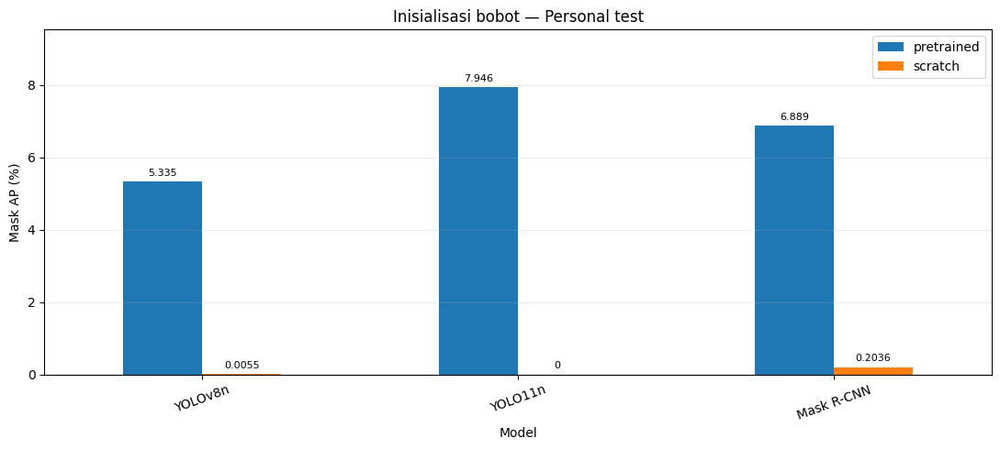

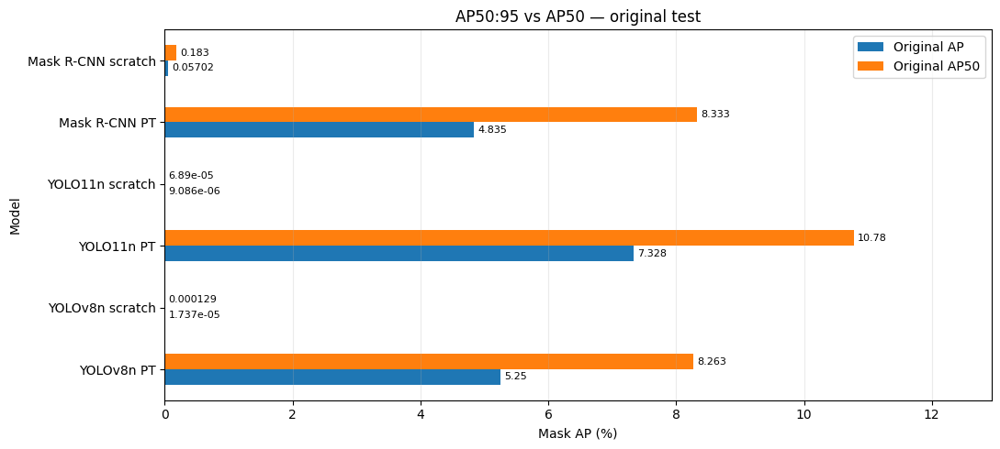

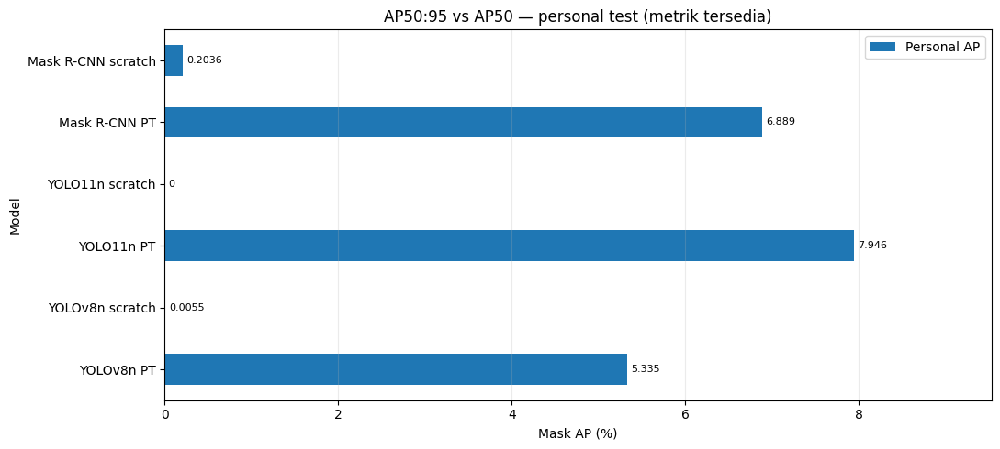

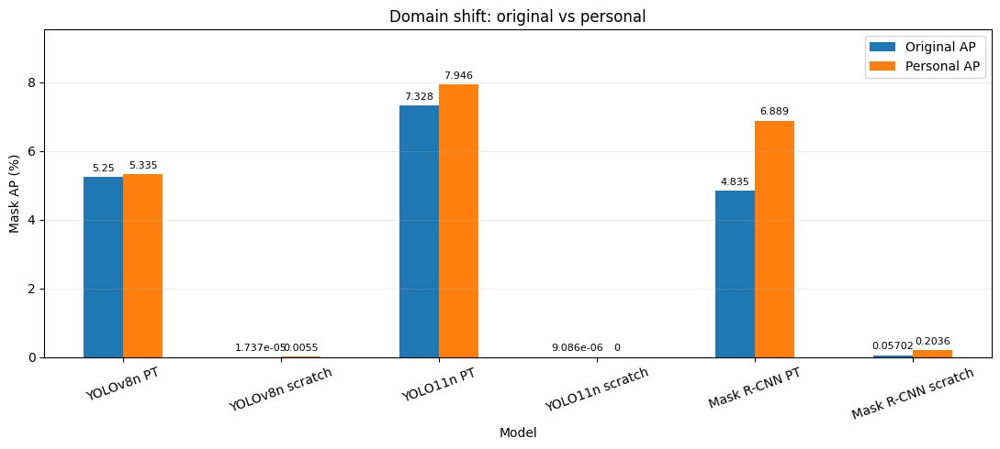

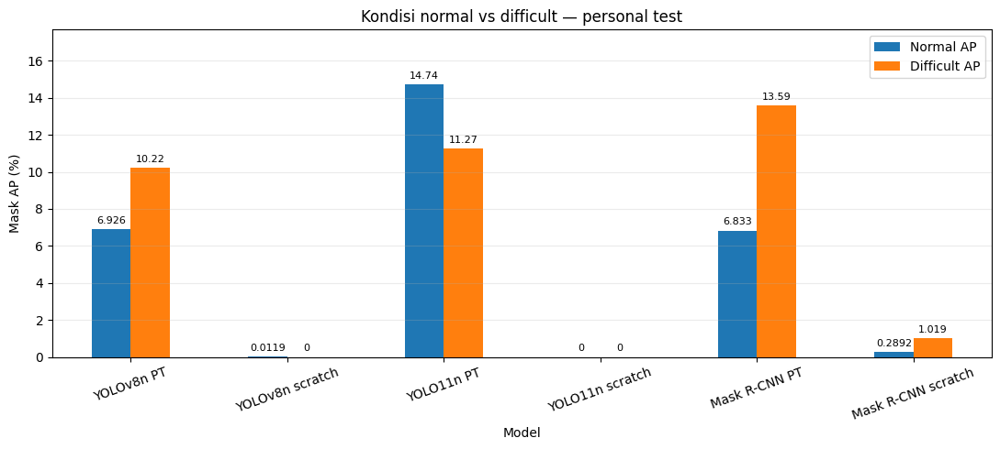

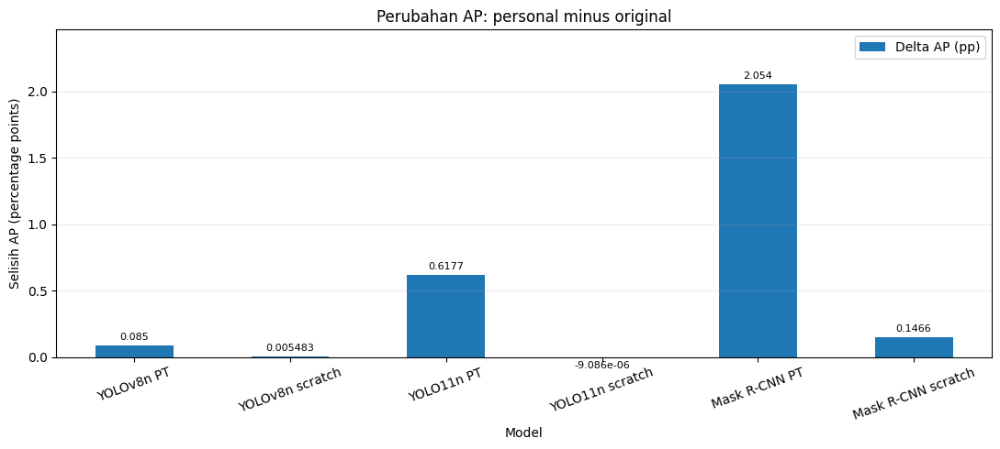

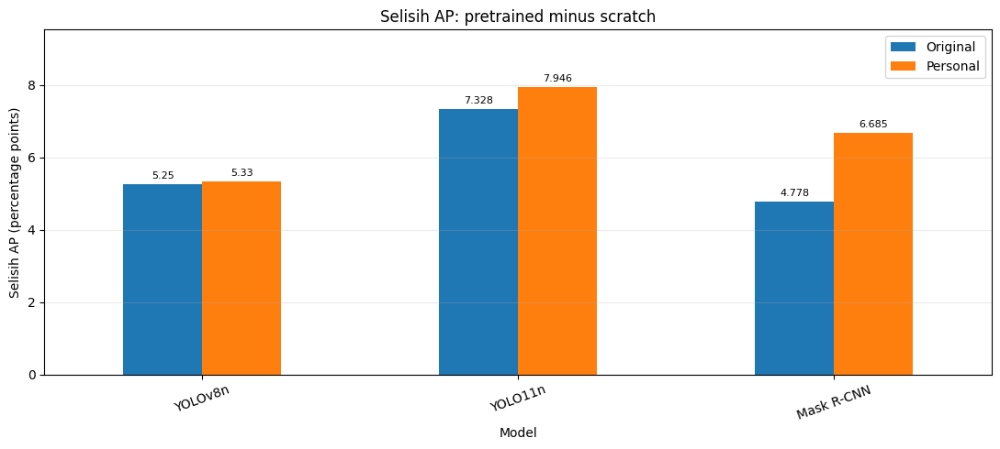

Interpretasi: bandingkan dataset dengan hati-hati; distribusi kelas, ukuran sampel, dan objek berbeda.


In [14]:
def finish(fig, filename):
    fig.tight_layout(); fig.savefig(FIG/(filename+'.png'),dpi=160,bbox_inches='tight'); plt.show(); plt.close(fig)

def bars(frame,title,filename,ylabel='Mask AP (%)', horizontal=False):
    if frame.dropna(how='all').empty:
        print('Tidak tersedia:',title); return
    frame.to_csv(OUTPUT_ROOT / (filename + '.csv'))
    frame=frame.dropna(how='all',axis=1)
    ax=frame.plot(kind='barh' if horizontal else 'bar',figsize=(11,5),rot=0 if horizontal else 20)
    for col,group in zip(frame.columns,ax.containers):
        labels=[f'{v:.4g}' if np.isfinite(v) else '' for v in frame[col].to_numpy(dtype=float)]
        ax.bar_label(group,labels=labels,padding=3,fontsize=8)
    ax.set_title(title); ax.set_xlabel(ylabel if horizontal else 'Model'); ax.set_ylabel('Model' if horizontal else ylabel)
    ax.grid(axis='x' if horizontal else 'y',alpha=.25); ax.margins(x=.20 if horizontal else .02,y=.06 if horizontal else .20)
    finish(ax.figure,filename)

for split in ['Original','Personal']:
    compare=pd.DataFrame({typ:[final_table.loc[f'{a}_{typ}',split+' AP'] for a in ['yolov8n','yolo11n','maskrcnn']] for typ in ['pretrained','scratch']},index=['YOLOv8n','YOLO11n','Mask R-CNN'])
    bars(compare,f'Inisialisasi bobot — {split} test',f'weights_{split.lower()}')
view=final_table.rename(index=LABELS)
bars(view[['Original AP','Original AP50']], 'AP50:95 vs AP50 — original test','original_ap_ap50',horizontal=True)
bars(view[['Personal AP','Personal AP50']], 'AP50:95 vs AP50 — personal test (metrik tersedia)','personal_ap_ap50',horizontal=True)
bars(view[['Original AP','Personal AP']], 'Domain shift: original vs personal','domain_shift')
bars(view[['Normal AP','Difficult AP']], 'Kondisi normal vs difficult — personal test','normal_difficult')
bars(view[['Delta AP (pp)']], 'Perubahan AP: personal minus original','domain_delta',ylabel='Selisih AP (percentage points)')
delta=pd.DataFrame({split:[final_table.loc[f'{a}_pretrained',split+' AP']-final_table.loc[f'{a}_scratch',split+' AP'] for a in ['yolov8n','yolo11n','maskrcnn']] for split in ['Original','Personal']},index=['YOLOv8n','YOLO11n','Mask R-CNN'])
bars(delta,'Selisih AP: pretrained minus scratch','pretrained_scratch_delta',ylabel='Selisih AP (percentage points)')
print('Interpretasi: bandingkan dataset dengan hati-hati; distribusi kelas, ukuran sampel, dan objek berbeda.')

## 04 — AP per kelas dan perbandingan kelas yang sama
Kelas tanpa ground truth tidak dianggap AP=0. Grafik hanya memakai kelas dengan data asli. AP antar-split dapat dipengaruhi perbedaan kelas yang hadir.

                  Model      Split AP per kelas  \
0    yolov8n_pretrained   original     tersedia   
1    yolov8n_pretrained        all  unavailable   
2    yolov8n_pretrained     normal  unavailable   
3    yolov8n_pretrained  difficult  unavailable   
4       yolov8n_scratch   original  unavailable   
5       yolov8n_scratch        all  unavailable   
6       yolov8n_scratch     normal  unavailable   
7       yolov8n_scratch  difficult  unavailable   
8    yolo11n_pretrained   original  unavailable   
9    yolo11n_pretrained        all  unavailable   
10   yolo11n_pretrained     normal  unavailable   
11   yolo11n_pretrained  difficult  unavailable   
12      yolo11n_scratch   original  unavailable   
13      yolo11n_scratch        all  unavailable   
14      yolo11n_scratch     normal  unavailable   
15      yolo11n_scratch  difficult  unavailable   
16  maskrcnn_pretrained   original  unavailable   
17  maskrcnn_pretrained        all  unavailable   
18  maskrcnn_pretrained     nor

                 Model     Split  Class   GT         AP       AP50  \
12  yolov8n_pretrained  original  chair  353  18.936911  36.074105   

                                               Source  
12  e:\Coding\Python\Computer_Vision\Week_11\resul...  

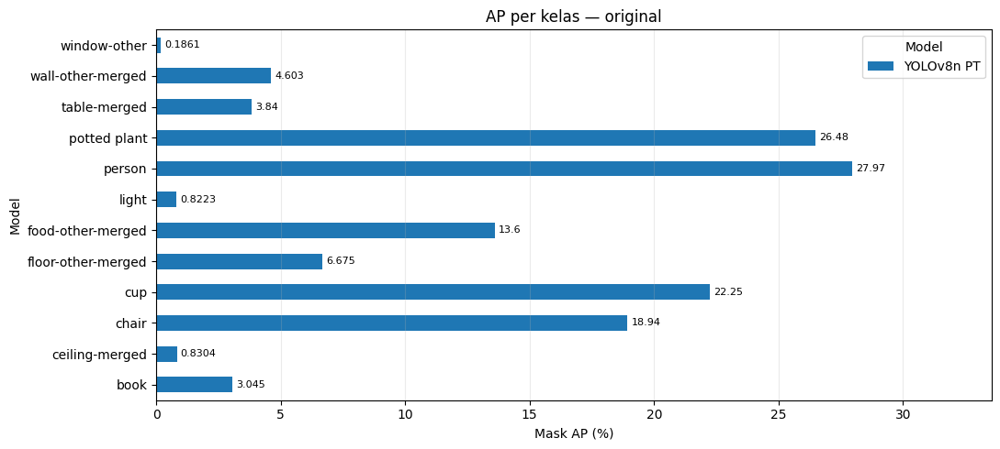

In [15]:
class_rows=[]
for run in RUNS:
    for split,m in {'original':RESULTS[run],**PERSONAL_RESULTS[run]}.items():
        for r in m.get('per_class',[]):
            class_rows.append({'Model':run,'Split':split,'Class':r['class'],'GT':r.get('ground_truth_instances'),'AP':metric(r,'ap'),'AP50':metric(r,'ap50'),'Source':SOURCES[run+'/'+split]})
class_table=pd.DataFrame(class_rows,columns=['Model','Split','Class','GT','AP','AP50','Source'])
class_table.to_csv(OUTPUT_ROOT/'per_class_percent.csv',index=False)
availability=pd.DataFrame([{'Model':run,'Split':split,'AP per kelas': 'tersedia' if any(x['Model']==run and x['Split']==split and pd.notna(x['AP']) for x in class_rows) else 'unavailable','Source':SOURCES[run+'/'+split]} for run in RUNS for split in ('original','all','normal','difficult')])
availability.to_csv(OUTPUT_ROOT/'per_class_availability.csv',index=False)
display(availability)
TARGET_CLASS='chair'  # easy live change
if class_table.empty:
    print('AP per kelas tidak terdapat di snapshot. Tambahkan output evaluation asli.')
else:
    display(class_table[class_table.Class==TARGET_CLASS])
    for split in class_table.Split.unique():
        t=class_table[(class_table.Split==split) & class_table.AP.notna()]
        if len(t):
            top=t.groupby('Class').GT.max().nlargest(12).index
            bars(t[t.Class.isin(top)].pivot_table(index='Class',columns='Model',values='AP').rename(columns=LABELS),f'AP per kelas — {split}',f'per_class_{split}',horizontal=True)

## 05 — Audit dataset dan distribusi kelas
Tidak mengunduh dataset atau mengonversi anotasi. Gunakan pemetaan COCO kanonik dari train, dan remap kategori personal berdasarkan nama persis.

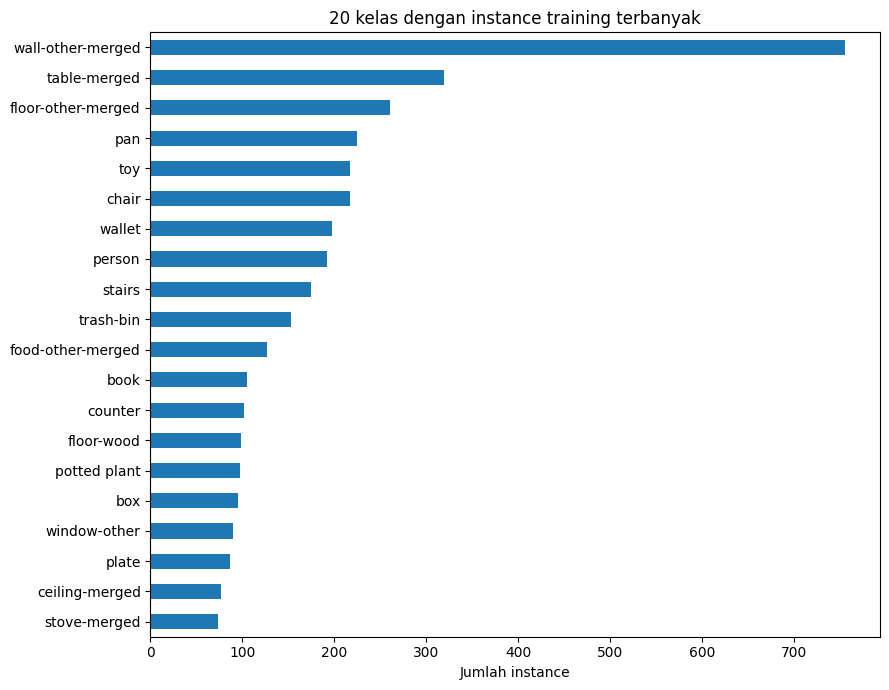

train    397
valid    166
test     359
Name: Jumlah foto, dtype: int64

{'photos': 41, 'difficult': 13, 'normal': 28, 'unmatched': [], 'extra': [], 'duplicate_metadata': False, 'duplicate_images': False, 'invalid_conditions': 0, 'eligible': True}


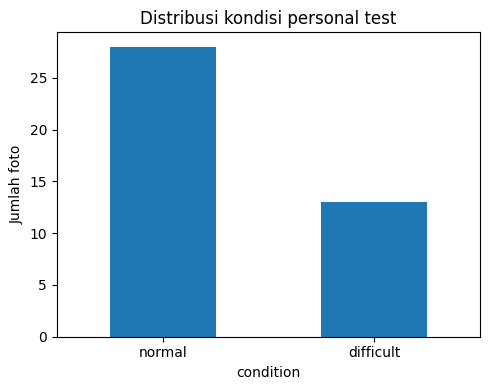

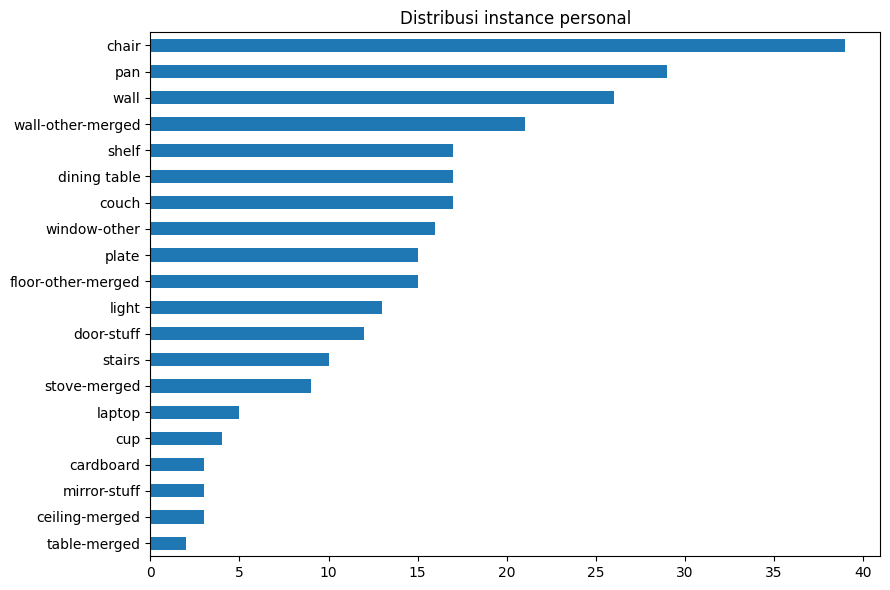

In [16]:
TRAIN_COCO=None; PERSONAL_COCO=None; META=None; PERSONAL_DIR=None; CLASS_NAMES=[]; CAT_NAMES={}; PERSONAL_OK=False
train_json=DATA_ROOT/'train/_annotations.coco.json'
if train_json.is_file():
    TRAIN_COCO=read_json(train_json)
    CAT_NAMES={c['id']:c['name'] for c in sorted(TRAIN_COCO['categories'],key=lambda c:c['id'])}
    CLASS_NAMES=list(CAT_NAMES.values())
    count=Counter(a['category_id'] for a in TRAIN_COCO['annotations'])
    freq=pd.Series({name:count[cid] for cid,name in CAT_NAMES.items()},name='instances').sort_values()
    freq.to_csv(OUTPUT_ROOT/'train_class_distribution.csv')
    ax=freq.tail(20).plot.barh(figsize=(9,7)); ax.set_title('20 kelas dengan instance training terbanyak'); ax.set_xlabel('Jumlah instance'); finish(ax.figure,'train_class_distribution')
    sizes={}
    for split in ['train','valid','test']:
        f=DATA_ROOT/split/'_annotations.coco.json'
        if split=='valid' and not f.is_file(): f=DATA_ROOT/'val/_annotations.coco.json'
        if f.is_file(): sizes[split]=len(read_json(f)['images'])
    display(pd.Series(sizes,name='Jumlah foto'))
else: print('Dataset sumber belum dipasang:',train_json)
if PERSONAL_ROOT.is_dir() and PERSONAL_METADATA.is_file() and CAT_NAMES:
    candidates=list(PERSONAL_ROOT.rglob('_annotations.coco.json'))
    if len(candidates)!=1: print('Butuh satu COCO personal:',candidates)
    else:
        f=candidates[0]; raw=read_json(f); META=pd.read_csv(PERSONAL_METADATA); PERSONAL_DIR=f.parent
        canon={v:k for k,v in CAT_NAMES.items()}; names=[c['name'] for c in raw['categories']]
        if len(names)!=len(set(names)) or not set(names)<=set(canon): raise ValueError('Kategori personal tidak konsisten dengan train')
        mapping={c['id']:canon[c['name']] for c in raw['categories']}
        for a in raw['annotations']: a['category_id']=mapping[a['category_id']]
        raw['categories']=TRAIN_COCO['categories']; PERSONAL_COCO=raw
        required={'filename','condition','difficulty_notes'}
        if not required<=set(META.columns): raise ValueError('Kolom metadata kurang: '+str(required-set(META.columns)))
        files=[i['file_name'] for i in raw['images']]; meta_files=META.filename.astype(str)
        conditions=META.condition.value_counts(); difficult=int(conditions.get('difficult',0))
        audit={'photos':len(files),'difficult':difficult,'normal':int(conditions.get('normal',0)),'unmatched':sorted(set(files)-set(meta_files)),'extra':sorted(set(meta_files)-set(files)),'duplicate_metadata':bool(meta_files.duplicated().any()),'duplicate_images':len(files)!=len(set(files)),'invalid_conditions':int((~META.condition.isin(['normal','difficult'])).sum())}
        PERSONAL_OK=len(files)>=40 and difficult>=10 and not any(audit[k] for k in ['unmatched','extra','duplicate_metadata','duplicate_images','invalid_conditions'])
        audit['eligible']=PERSONAL_OK; print(audit)
        (OUTPUT_ROOT/'personal_audit.json').write_text(json.dumps(audit,indent=2),encoding='utf-8')
        ax=conditions.plot.bar(rot=0,figsize=(5,4)); ax.set_title('Distribusi kondisi personal test'); ax.set_ylabel('Jumlah foto'); finish(ax.figure,'personal_conditions')
        ct=Counter(a['category_id'] for a in raw['annotations']); f=pd.Series({CAT_NAMES[k]:v for k,v in ct.items()}).sort_values()
        f.to_csv(OUTPUT_ROOT/'personal_class_distribution.csv')
        if len(f):
            ax=f.tail(20).plot.barh(figsize=(9,6)); ax.set_title('Distribusi instance personal'); finish(ax.figure,'personal_classes')
else: print(f'Audit personal dilewati: butuh metadata asli {PERSONAL_METADATA}, dataset personal, dan dataset sumber.')

## 06 — Lima studi kasus kegagalan personal test
Memilih foto berdasarkan bukti kegagalan mask pada threshold diagnostik 0.14 dan IoU 0.50. Pencocokan greedy satu-ke-satu, per kelas, bukan COCO AP. Kasus ditampilkan dengan prediksi asli, GT, dan daftar objek yang gagal; dugaan sebab perlu inspeksi visual dan tidak disimpulkan otomatis. Jika cache tidak ada, aktifkan inferensi terbatas (maksimum 8 foto) pada konfigurasi; hasilnya bukan evaluasi full dataset. Kasus tidak dipaksakan menjadi lima bila bukti tidak mencukupi.

creating index...
index created!


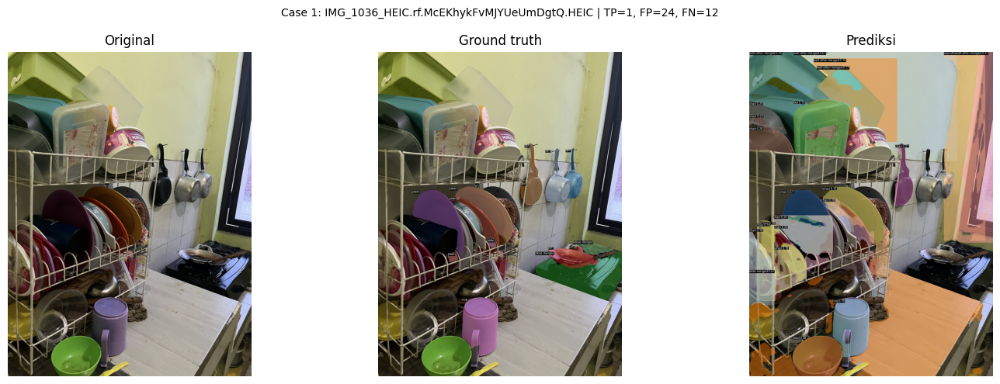

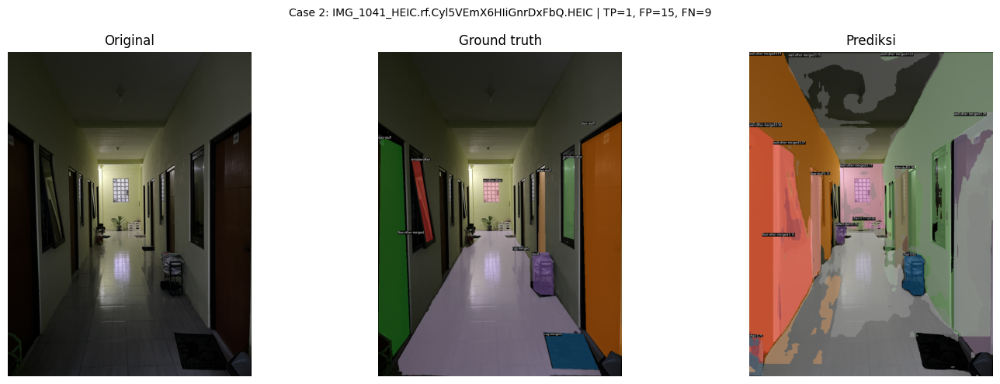

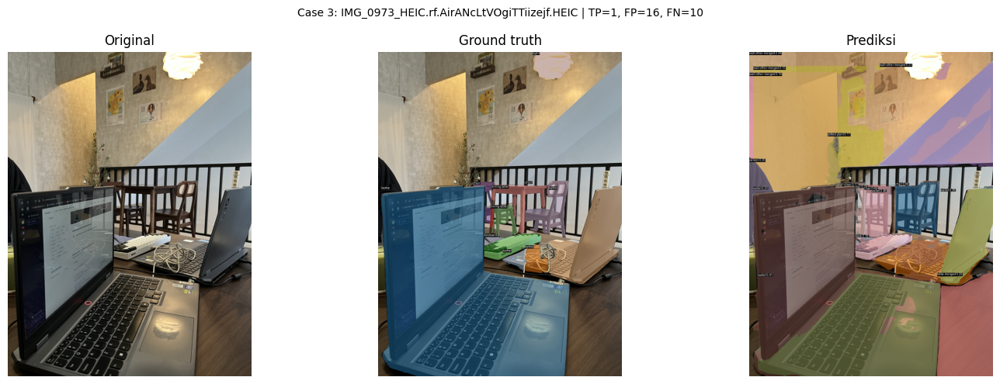

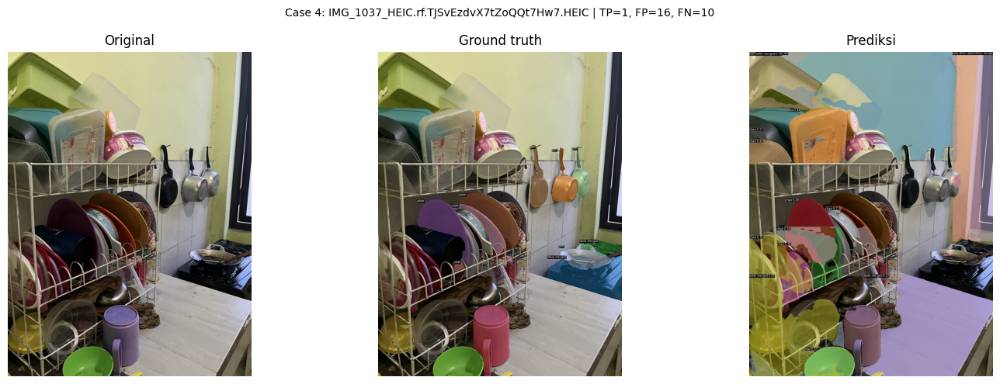

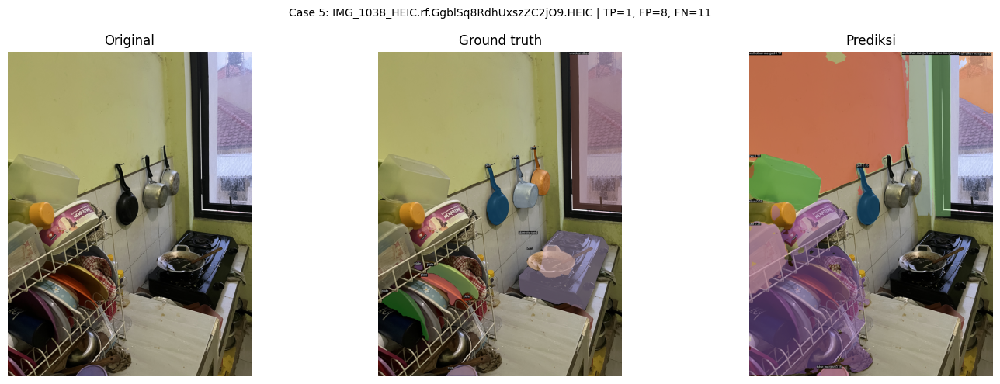

   case                                    filename               model  \
0     1  IMG_1036_HEIC.rf.McEKhykFvMJYUeUmDgtQ.HEIC  yolo11n_pretrained   
1     2  IMG_1041_HEIC.rf.Cyl5VEmX6HIiGnrDxFbQ.HEIC  yolo11n_pretrained   
2     3  IMG_0973_HEIC.rf.AirANcLtVOgiTTiizejf.HEIC  yolo11n_pretrained   
3     4  IMG_1037_HEIC.rf.TJSvEzdvX7tZoQQt7Hw7.HEIC  yolo11n_pretrained   
4     5  IMG_1038_HEIC.rf.GgblSq8RdhUxszZC2jO9.HEIC  yolo11n_pretrained   

   condition                                   difficulty_notes  GT  TP  FN  \
0  difficult     Occlusion: stacked plates and kitchen utensils  13   1  12   
1  difficult  Low light and backlight: dark corridor with br...  10   1   9   
2     normal  No pronounced difficult condition in visual re...  11   1  10   
3  difficult              Occlusion: overlapping dishes in rack  11   1  10   
4  difficult  Occlusion: overlapping plates and kitchen objects  12   1  11   

   FP  small_GT  small_TP                                             miss

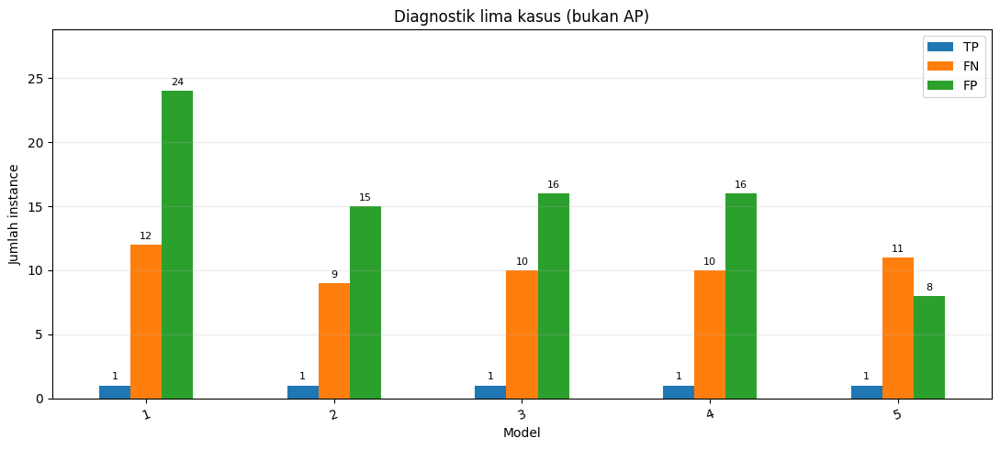

5 kasus terbukti secara diagnostik; verifikasi visual dan isi analisis mekanisme per kasus.


In [17]:
CASE_ROWS=[]; CASE_RECORDS=[]; CASE_DETAILS={}; CASE_PRED={}; CASE_SOURCE=None; API=None; mu=None

def dependencies():
    global mu, API
    from pycocotools import mask as mu
    from pycocotools.coco import COCO
    API=COCO(); API.dataset=PERSONAL_COCO; API.createIndex()

def photo_path(rec):
    root=PERSONAL_DIR.resolve()
    for name in (rec['file_name'], rec.get('extra', {}).get('name', '')):
        if not name: continue
        p=(root/name).resolve(); p.relative_to(root)
        if p.is_file():
            if p.suffix.lower() in ('.heic', '.heif'):
                from pillow_heif import register_heif_opener
                register_heif_opener()
            return p
    raise FileNotFoundError(f"Foto personal tidak ditemukan: {rec['file_name']}")

def binary_rle(mask):
    r=mu.encode(np.asfortranarray(mask.astype('uint8'))); r['counts']=r['counts'].decode('ascii'); return r

def rle_for_api(r):
    return {**r,'counts':r['counts'].encode('ascii') if isinstance(r['counts'],str) else r['counts']}

def yolo_predictions(run, records, size, conf, max_det=30):
    # Only called for bounded diagnostic/demo inference. No model training.
    import torch, gc
    from ultralytics import YOLO
    from PIL import Image
    if not run.startswith(('yolov8','yolo11')): raise ValueError('Diagnostic inference supports YOLO only.')
    checkpoint=CHECKPOINTS[run]
    if not checkpoint.is_file(): raise FileNotFoundError(checkpoint)
    model=YOLO(str(checkpoint)); model_names=[model.names[i] for i in range(len(model.names))]
    if model_names!=CLASS_NAMES: raise ValueError('Class mapping checkpoint berbeda dari train.')
    device=0 if torch.cuda.is_available() else 'cpu'
    output=[]
    try:
        for rec in records:
            with Image.open(photo_path(rec)) as im: rgb=im.convert('RGB')
            if rgb.size!=(rec['width'],rec['height']): raise ValueError('Dimensi foto berbeda dari COCO: '+rec['file_name'])
            # Resize only the source passed to the predictor to bound native masks.
            rgb.thumbnail((960,960))
            def predict(dev): return model.predict(source=rgb,imgsz=size,conf=conf,iou=.7,max_det=max_det,retina_masks=True,device=dev,verbose=False)[0]
            try: res=predict(device)
            except torch.cuda.OutOfMemoryError:
                if device=='cpu': raise
                device='cpu'; model.to('cpu'); gc.collect(); torch.cuda.empty_cache(); res=predict(device)
            res=res.cpu()
            if res.masks is not None:
                for mask,cls,score in zip(res.masks.data.numpy(),res.boxes.cls.numpy(),res.boxes.conf.numpy()):
                    m=Image.fromarray((mask>.5).astype('uint8')).resize((rec['width'],rec['height']),Image.Resampling.NEAREST)
                    output.append({'image_id':rec['id'],'category_id':list(CAT_NAMES)[int(cls)],'score':float(score),'segmentation':binary_rle(np.array(m)>0)})
            del res
    finally:
        del model; gc.collect()
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    return output

def match_case(rec,preds,small_only=False):
    gts=[a for a in API.imgToAnns[rec['id']] if not a.get('iscrowd',0) and a.get('area',0)>0]
    preds=sorted([p for p in preds if p['score']>=CASE_CONF],key=lambda p:-p['score'])
    gtr=[API.annToRLE(a) for a in gts]; pr=[rle_for_api(p['segmentation']) for p in preds]
    ious=mu.iou(pr,gtr,[0]*len(gts)) if pr and gtr else np.zeros((len(pr),len(gtr)))
    matched={}; fp=[]
    for i,p in enumerate(preds):
        options=[j for j,a in enumerate(gts) if j not in matched and a['category_id']==p['category_id'] and ious[i,j]>=MATCH_IOU]
        if options:
            j=max(options,key=lambda j:ious[i,j]); matched[j]=i
        else: fp.append(i)
    misses=[]
    for j,a in enumerate(gts):
        if j in matched: continue
        same=[i for i,p in enumerate(preds) if p['category_id']==a['category_id']]
        best=max([float(ious[i,j]) for i in same],default=0.)
        wrong=any(ious[i,j]>=MATCH_IOU and p['category_id']!=a['category_id'] for i,p in enumerate(preds))
        reason='overlap kelas berbeda' if wrong else ('mask overlap rendah / duplikat' if best>0 else 'tidak ada overlap sekelas')
        misses.append({'class':CAT_NAMES[a['category_id']],'reason':reason,'best_same_class_iou':best,'small':a['area']/(rec['width']*rec['height'])<.02})
    small=[j for j,a in enumerate(gts) if a['area']/(rec['width']*rec['height'])<.02]
    return {'gt':len(gts),'pred':len(preds),'tp':len(matched),'fn':len(misses),'fp':len(fp),'matched_ious':[float(ious[i,j]) for j,i in matched.items()],'small_gt':len(small),'small_tp':sum(j in matched for j in small),'misses':misses,'false_positives':[{'class':CAT_NAMES[preds[i]['category_id']],'score':preds[i]['score'],'reason':'tidak cocok sekelas pada IoU ≥ 0.50'} for i in fp],'preds':preds,'gts':gts}

def render_overlay(rec, annotations, pred=False):
    from PIL import Image, ImageDraw
    with Image.open(photo_path(rec)) as im: rgb=im.convert('RGB')
    rgb.thumbnail((1100,1100)); w,h=rgb.size; base=np.array(rgb).copy(); labels=[]
    for j,a in enumerate(annotations):
        rle=rle_for_api(a['segmentation']) if pred else API.annToRLE(a)
        mask=mu.decode(rle)
        if mask.ndim==3: mask=mask.any(axis=2)
        if mask.shape!=(rec['height'],rec['width']): raise ValueError('Mask tidak sesuai dimensi COCO')
        m=np.array(Image.fromarray(mask.astype('uint8')).resize((w,h),Image.Resampling.NEAREST)).astype(bool)
        color=np.array(plt.cm.tab20(j%20)[:3])*255
        base[m]=(.55*base[m]+.45*color).astype('uint8')
        ys,xs=np.where(m)
        if len(xs): labels.append((int(xs.min()),int(ys.min()),CAT_NAMES.get(a['category_id'],str(a['category_id']))+(f' {a["score"]:.2f}' if pred else '')))
    im=Image.fromarray(base); draw=ImageDraw.Draw(im)
    for x,y,t in labels:
        box=draw.textbbox((x,y),t); draw.rectangle(box,fill='black'); draw.text((x,y),t,fill='white')
    return im

if PERSONAL_OK:
    try: dependencies()
    except ImportError as e: print('Instal pycocotools untuk analisis:',e)
if API is not None:
    caches=[BASE_ROOT / x['path'] for x in inventory if Path(x['path']).name.lower()=='predictions.json' and 'personal' in str(x['path']).lower() and FAILURE_MODEL in str(x['path']).lower()]
    if len(caches)>1: raise ValueError(f'Cache personal ambigu: {caches}')
    cache=caches[0] if caches else None
    records=PERSONAL_COCO['images']; by_id={r['id']:r for r in records}; by_name={r['file_name']:r for r in records}
    if CASE_FILENAMES:
        if len(set(CASE_FILENAMES))!=len(CASE_FILENAMES) or len(CASE_FILENAMES)>5 or not set(CASE_FILENAMES)<=set(by_name): raise ValueError('CASE_FILENAMES harus unik, maksimal 5, dan ada di personal test')
        candidates=[by_name[n] for n in CASE_FILENAMES]
    else: candidates=records
    old_cache=BASE_ROOT/'results'/'analisis_final'/'diagnostic_predictions.json'
    old_info=old_cache.with_name('case_prediction_source.json')
    if not cache and not CASE_FILENAMES and old_cache.is_file() and old_info.is_file():
        info=read_json(old_info)
        if info.get('confidence')==CASE_CONF and info.get('imgsz')==640 and Path(info.get('model','')).name==CHECKPOINTS[FAILURE_MODEL].name:
            ids=info.get('candidate_image_ids',[])
            if ids and set(ids)<=set(by_id): cache=old_cache; candidates=[by_id[i] for i in ids]
    if cache and cache.is_file():
        data=read_json(cache)
        if not isinstance(data,list) or any(p['image_id'] not in by_id or p['category_id'] not in CAT_NAMES for p in data): raise ValueError('Cache prediksi tidak sesuai personal COCO')
        CASE_SOURCE=str(cache)
    elif RUN_CASE_INFERENCE_IF_MISSING:
        def candidate_key(rec):
            anns=[a for a in API.imgToAnns[rec['id']] if not a.get('iscrowd',0) and a.get('area',0)>0]
            small=sum(a['area']/(rec['width']*rec['height'])<.02 for a in anns)
            return (small, len({a['category_id'] for a in anns}), len(anns))
        candidates=sorted(candidates,key=candidate_key,reverse=True)[:8]
        pd.DataFrame([{'image_id':r['id'],'filename':r['file_name'],'small_gt':candidate_key(r)[0],'class_count':candidate_key(r)[1],'gt_count':candidate_key(r)[2]} for r in candidates]).to_csv(OUTPUT_ROOT/'candidate_selection.csv',index=False)
        data=yolo_predictions(FAILURE_MODEL,candidates,640,CASE_CONF); CASE_SOURCE='inferensi diagnostik terbatas; bukan evaluasi penuh'
    else:
        data=None; print('Cache personal tidak tersedia. Pasang output lama atau aktifkan RUN_CASE_INFERENCE_IF_MISSING.')
    if data is not None:
        (OUTPUT_ROOT/'diagnostic_predictions.json').write_text(json.dumps(data),encoding='utf-8')
        (OUTPUT_ROOT/'case_prediction_source.json').write_text(json.dumps({'source':CASE_SOURCE,'candidate_image_ids':[r['id'] for r in candidates],'confidence':CASE_CONF,'imgsz':640,'model':str(CHECKPOINTS[FAILURE_MODEL])},indent=2),encoding='utf-8')
        for p in data: CASE_PRED.setdefault(p['image_id'],[]).append(p)
        for rec in candidates:
            d=match_case(rec,CASE_PRED.get(rec['id'],[])); CASE_DETAILS[rec['id']]=d
        pd.DataFrame([{'image_id':r['id'],'filename':r['file_name'],**{k:v for k,v in CASE_DETAILS[r['id']].items() if k not in ('preds','gts')}} for r in candidates]).to_csv(OUTPUT_ROOT/'candidate_metrics.csv',index=False)
        failures=[r for r in candidates if CASE_DETAILS[r['id']]['fn']+CASE_DETAILS[r['id']]['fp']>0]
        CASE_RECORDS=(failures if CASE_FILENAMES else sorted(failures,key=lambda r:-(CASE_DETAILS[r['id']]['fn']+CASE_DETAILS[r['id']]['fp'])/max(1,CASE_DETAILS[r['id']]['gt'])))[:5]
        case_dir=OUTPUT_ROOT/'failure_analysis'; case_dir.mkdir(exist_ok=True)
        from PIL import Image
        for i,rec in enumerate(CASE_RECORDS,1):
            d=CASE_DETAILS[rec['id']]; meta=META.loc[META.filename==rec['file_name']].iloc[0]
            fig,ax=plt.subplots(1,3,figsize=(15,5))
            with Image.open(photo_path(rec)) as im: raw=im.convert('RGB'); raw.thumbnail((1100,1100))
            for a,im,title in zip(ax,[raw,render_overlay(rec,d['gts']),render_overlay(rec,d['preds'],True)],['Original','Ground truth','Prediksi']): a.imshow(im); a.set_title(title); a.axis('off')
            fig.suptitle(f'Case {i}: {rec["file_name"]} | TP={d["tp"]}, FP={d["fp"]}, FN={d["fn"]}',fontsize=10); fig.tight_layout(); fig.savefig(case_dir/f'case_{i:02}.png',dpi=140,bbox_inches='tight'); plt.show(); plt.close(fig)
            row={'case':i,'filename':rec['file_name'],'model':FAILURE_MODEL,'condition':meta['condition'],'difficulty_notes':meta['difficulty_notes'],'GT':d['gt'],'TP':d['tp'],'FN':d['fn'],'FP':d['fp'],'small_GT':d['small_gt'],'small_TP':d['small_tp'],'misses':json.dumps(d['misses'],ensure_ascii=False),'false_positives':json.dumps(d['false_positives'],ensure_ascii=False),'source':CASE_SOURCE,'confidence':CASE_CONF,'match_iou':MATCH_IOU,'analisis_arsitektur_manual':'ISI setelah inspeksi visual'}
            CASE_ROWS.append(row)
        pd.DataFrame(CASE_ROWS).to_csv(case_dir/'cases.csv',index=False); display(pd.DataFrame(CASE_ROWS))
        if CASE_ROWS: bars(pd.DataFrame(CASE_ROWS).set_index('case')[['TP','FN','FP']], 'Diagnostik lima kasus (bukan AP)','failure_counts',ylabel='Jumlah instance')
        print(f'{len(CASE_RECORDS)} kasus terbukti secara diagnostik; verifikasi visual dan isi analisis mekanisme per kasus.')
else: print('Analisis kegagalan menunggu dataset personal dan pycocotools.')

## 07 — Eksperimen pembuktian: pretrained versus from scratch
Untuk setiap arsitektur, kedua checkpoint memproses lima foto yang sama dengan threshold dan konfigurasi identik. Pencocokan greedy satu-ke-satu berdasarkan kelas dan IoU ≥ 0.50. Rata-rata IoU hanya atas pasangan yang cocok; tanpa pasangan nilainya unavailable. Ini diagnostik lima foto, bukan mAP dataset; perbedaan antar-arsitektur memiliki preprocessing internal berbeda.

    case                                    filename                model  TP  \
0      1  IMG_1036_HEIC.rf.McEKhykFvMJYUeUmDgtQ.HEIC   yolov8n_pretrained   1   
1      2  IMG_1041_HEIC.rf.Cyl5VEmX6HIiGnrDxFbQ.HEIC   yolov8n_pretrained   1   
2      3  IMG_0973_HEIC.rf.AirANcLtVOgiTTiizejf.HEIC   yolov8n_pretrained   1   
3      4  IMG_1037_HEIC.rf.TJSvEzdvX7tZoQQt7Hw7.HEIC   yolov8n_pretrained   1   
4      5  IMG_1038_HEIC.rf.GgblSq8RdhUxszZC2jO9.HEIC   yolov8n_pretrained   0   
5      1  IMG_1036_HEIC.rf.McEKhykFvMJYUeUmDgtQ.HEIC      yolov8n_scratch   0   
6      2  IMG_1041_HEIC.rf.Cyl5VEmX6HIiGnrDxFbQ.HEIC      yolov8n_scratch   0   
7      3  IMG_0973_HEIC.rf.AirANcLtVOgiTTiizejf.HEIC      yolov8n_scratch   0   
8      4  IMG_1037_HEIC.rf.TJSvEzdvX7tZoQQt7Hw7.HEIC      yolov8n_scratch   0   
9      5  IMG_1038_HEIC.rf.GgblSq8RdhUxszZC2jO9.HEIC      yolov8n_scratch   0   
10     1  IMG_1036_HEIC.rf.McEKhykFvMJYUeUmDgtQ.HEIC   yolo11n_pretrained   1   
11     2  IMG_1041_HEIC.rf.C

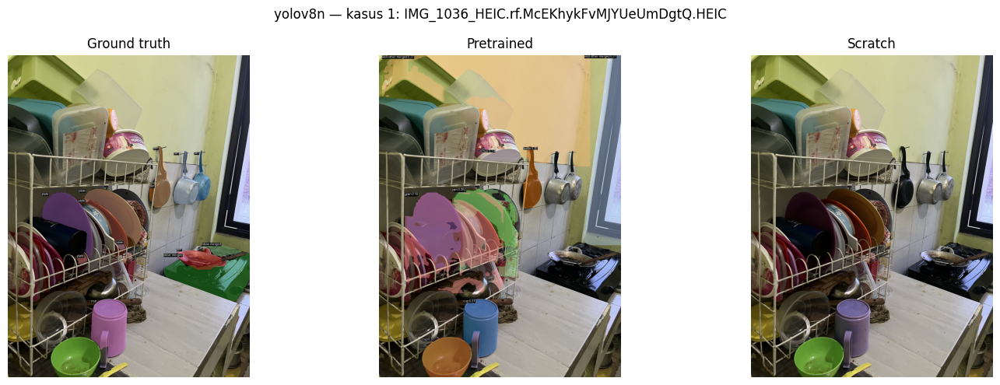

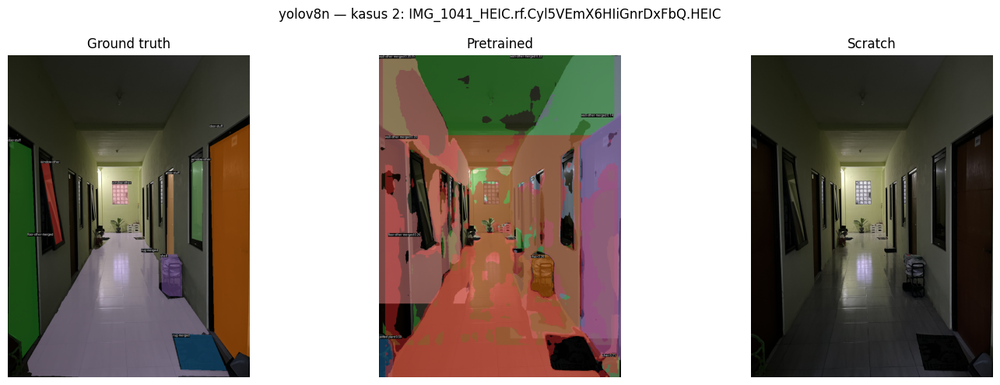

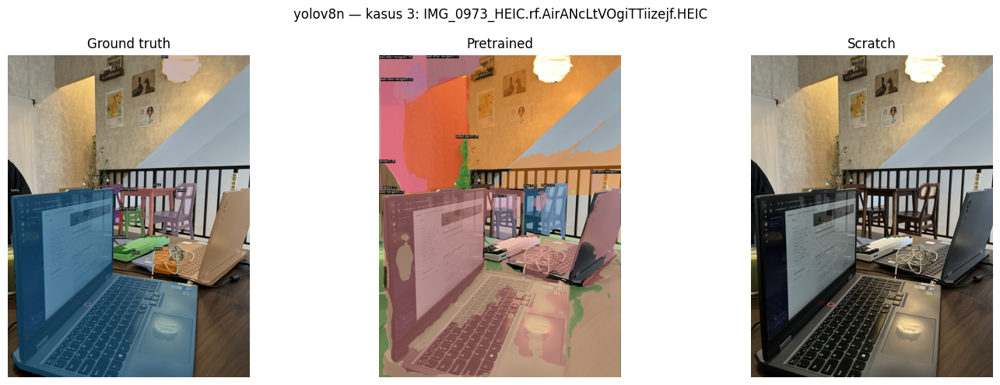

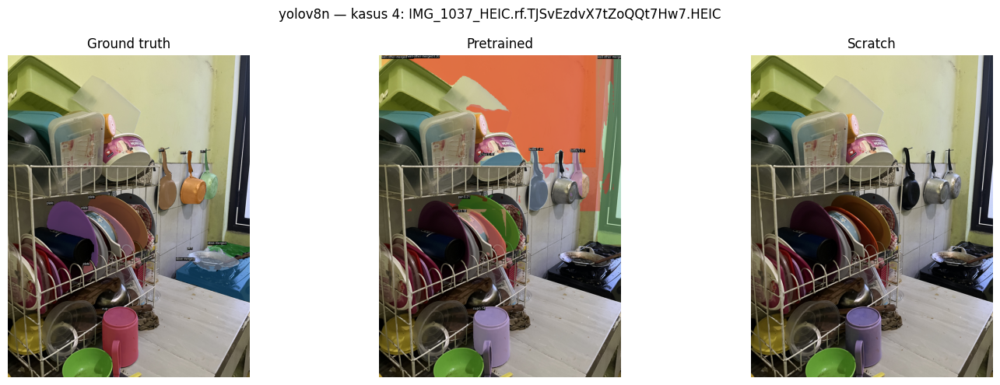

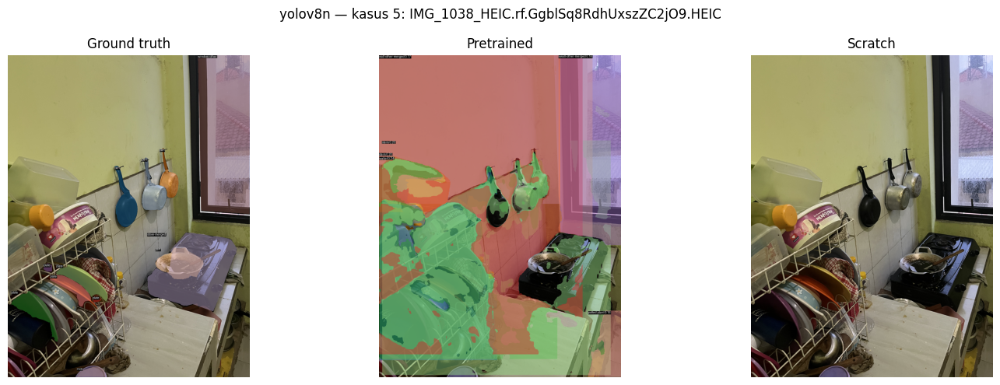

...

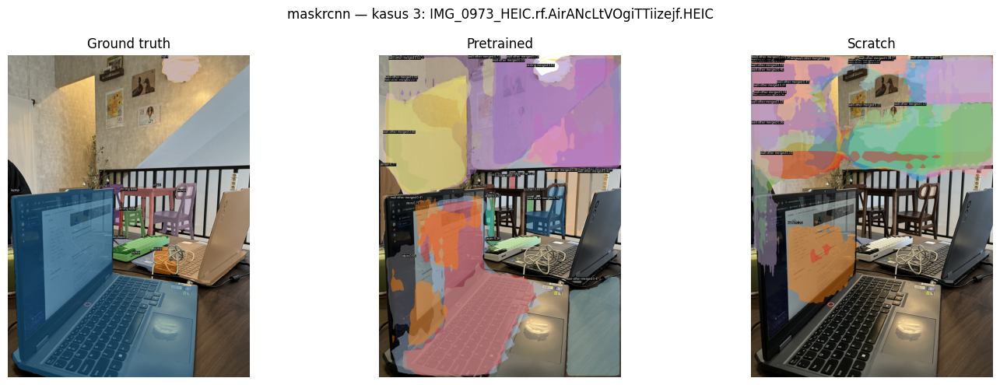

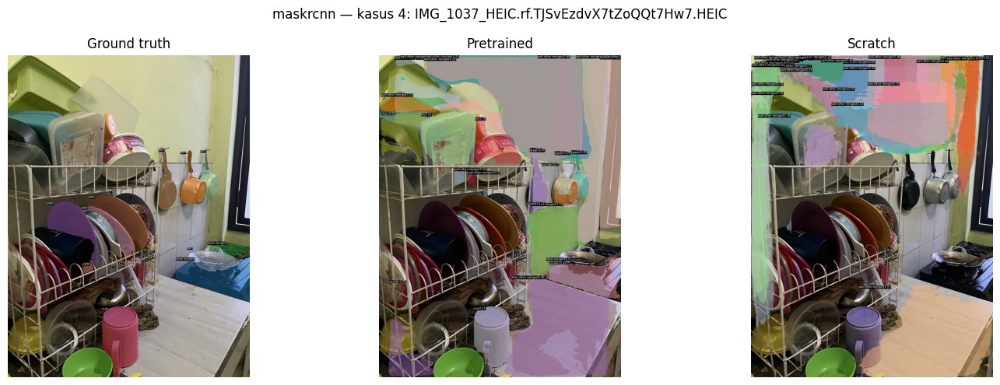

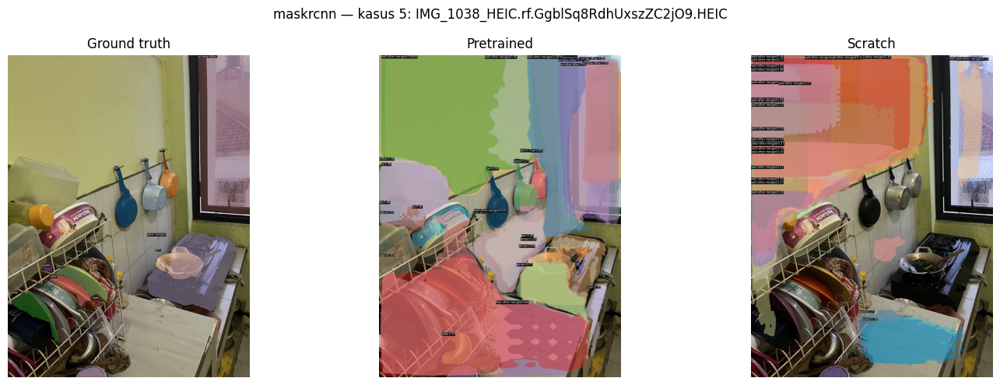

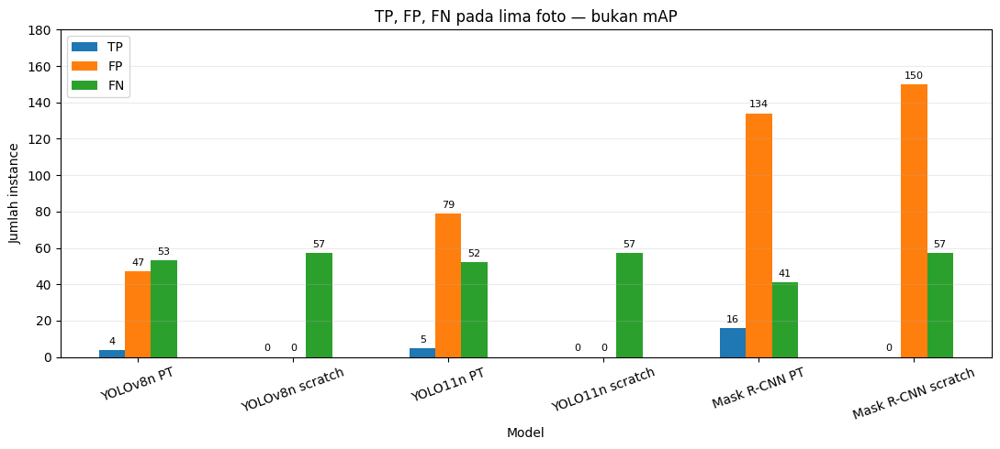

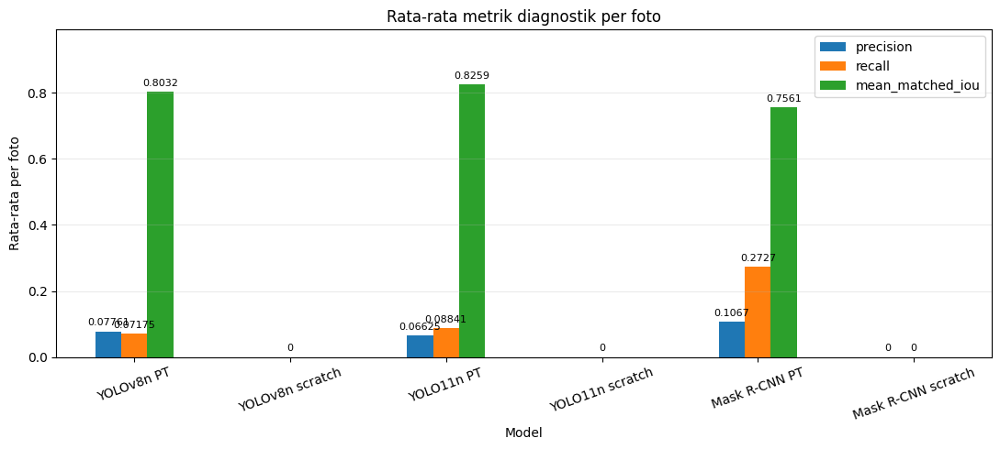

Rata-rata per foto; IoU hanya untuk pasangan cocok, dan nilai tidak tersedia dikecualikan. Bandingkan per arsitektur; tidak membuktikan model selalu unggul.
yolov8n: pretrained TP=4, FP=47, FN=53; scratch TP=0, FP=0, FN=57 pada lima foto.
yolo11n: pretrained TP=5, FP=79, FN=52; scratch TP=0, FP=0, FN=57 pada lima foto.
maskrcnn: pretrained TP=16, FP=134, FN=41; scratch TP=0, FP=150, FN=57 pada lima foto.


In [18]:
WEIGHT_RESULT=None
if API is not None and CASE_RECORDS:
    import torch, gc
    from PIL import Image
    from torchvision.models.detection import maskrcnn_resnet50_fpn
    from torchvision.transforms.functional import pil_to_tensor
    def maskrcnn_predictions(run, records):
        model=maskrcnn_resnet50_fpn(weights=None,weights_backbone=None,num_classes=len(CLASS_NAMES)+1)
        model.load_state_dict(torch.load(CHECKPOINTS[run],map_location='cpu',weights_only=True),strict=True)
        model.roi_heads.score_thresh=CASE_CONF
        model.roi_heads.nms_thresh=.7
        model.roi_heads.detections_per_img=30
        device='cuda' if torch.cuda.is_available() else 'cpu'
        model.eval().to(device)
        out=[]
        try:
            for rec in records:
                with Image.open(photo_path(rec)) as im:
                    image=im.convert('RGB'); image.thumbnail((960,960))
                tensor=pil_to_tensor(image).float().div_(255).to(device)
                with torch.inference_mode():
                    result=model([tensor])[0]
                for mask,label,score in zip(result['masks'],result['labels'],result['scores']):
                    m=Image.fromarray((mask[0].cpu().numpy()>=.5).astype('uint8')).resize((rec['width'],rec['height']),Image.Resampling.NEAREST)
                    out.append({'image_id':rec['id'],'category_id':list(CAT_NAMES)[int(label)-1],'score':float(score),'segmentation':binary_rle(np.array(m)>0)})
                del result,tensor
        finally:
            del model; gc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        return out
    experiment_dir=OUTPUT_ROOT/'weight_experiment'; experiment_dir.mkdir(exist_ok=True)
    import hashlib
    def sha256_file(path):
        h=hashlib.sha256()
        with open(path,'rb') as f:
            for block in iter(lambda:f.read(1024*1024),b''): h.update(block)
        return h.hexdigest()
    image_hashes={str(r['id']):sha256_file(photo_path(r)) for r in CASE_RECORDS}
    exp_rows=[]; exp_predictions={}
    for run in RUNS:
        pred_file=experiment_dir/f'{run}_predictions.json'
        manifest_file=experiment_dir/f'{run}_manifest.json'
        signature={'checkpoint_sha256':sha256_file(CHECKPOINTS[run]),'image_sha256':image_hashes,'confidence':CASE_CONF,'nms_iou':.7,'max_det':30,'yolo_imgsz':640,'source_max_side':960,'model':run}
        if pred_file.is_file() and manifest_file.is_file() and read_json(manifest_file).get('signature')==signature:
            preds=read_json(pred_file); source='cache eksperimen: '+str(pred_file)
        elif run==FAILURE_MODEL:
            preds=[p for rec in CASE_RECORDS for p in CASE_PRED.get(rec['id'],[])]
            source=CASE_SOURCE
        else:
            preds=maskrcnn_predictions(run,CASE_RECORDS) if run.startswith('maskrcnn') else yolo_predictions(run,CASE_RECORDS,640,CASE_CONF,max_det=30)
            source='inferensi terbatas pada lima foto'
        pred_file.write_text(json.dumps(preds),encoding='utf-8')
        manifest_file.write_text(json.dumps({'signature':signature,'source':source},indent=2),encoding='utf-8')
        exp_predictions[run]={r['id']:[] for r in CASE_RECORDS}
        for p in preds: exp_predictions[run][p['image_id']].append(p)
        for number,rec in enumerate(CASE_RECORDS,1):
            d=match_case(rec,exp_predictions[run][rec['id']]); tp,fp,fn=d['tp'],d['fp'],d['fn']
            exp_rows.append({'case':number,'filename':rec['file_name'],'model':run,'TP':tp,'FP':fp,'FN':fn,'precision':tp/(tp+fp) if tp+fp else np.nan,'recall':tp/(tp+fn) if tp+fn else np.nan,'mean_matched_iou':float(np.mean(d['matched_ious'])) if d['matched_ious'] else np.nan,'matched_ious':d['matched_ious'],'source':source})
    exp_table=pd.DataFrame(exp_rows)
    exp_table.to_csv(experiment_dir/'metrics.csv',index=False); display(exp_table.drop(columns=['matched_ious']))
    for arch in ('yolov8n','yolo11n','maskrcnn'):
        for number,rec in enumerate(CASE_RECORDS,1):
            gt=CASE_DETAILS[rec['id']]['gts']
            fig,axes=plt.subplots(1,3,figsize=(15,5))
            images=[render_overlay(rec,gt),render_overlay(rec,exp_predictions[arch+'_pretrained'][rec['id']],True),render_overlay(rec,exp_predictions[arch+'_scratch'][rec['id']],True)]
            for ax,img,title in zip(axes,images,['Ground truth','Pretrained','Scratch']): ax.imshow(img); ax.set_title(title); ax.axis('off')
            fig.suptitle(f'{arch} — kasus {number}: {rec["file_name"]}')
            fig.tight_layout(); fig.savefig(experiment_dir/f'{arch}_case_{number:02}.png',dpi=130,bbox_inches='tight'); plt.show(); plt.close(fig)
    grouped=exp_table.groupby('model')[['TP','FP','FN']].sum().reindex(RUNS)
    bars(grouped.rename(index=LABELS),'TP, FP, FN pada lima foto — bukan mAP','weight_experiment_counts',ylabel='Jumlah instance')
    summary=exp_table.groupby('model')[['precision','recall','mean_matched_iou']].mean().reindex(RUNS)
    bars(summary.rename(index=LABELS),'Rata-rata metrik diagnostik per foto','weight_experiment_quality',ylabel='Rata-rata per foto')
    print('Rata-rata per foto; IoU hanya untuk pasangan cocok, dan nilai tidak tersedia dikecualikan. Bandingkan per arsitektur; tidak membuktikan model selalu unggul.')
    interpretation=[]
    for arch in ('yolov8n','yolo11n','maskrcnn'):
        a=grouped.loc[arch+'_pretrained']; b=grouped.loc[arch+'_scratch']
        text=f"{arch}: pretrained TP={int(a.TP)}, FP={int(a.FP)}, FN={int(a.FN)}; scratch TP={int(b.TP)}, FP={int(b.FP)}, FN={int(b.FN)} pada lima foto."
        interpretation.append(text); print(text)
    (experiment_dir/'interpretation.txt').write_text('\n'.join(interpretation)+'\n',encoding='utf-8')
    WEIGHT_RESULT={'settings':{'confidence':CASE_CONF,'match_iou':MATCH_IOU,'nms_iou':.7,'max_det':30,'yolo_imgsz':640,'source_max_side':960,'maskrcnn_transform':'torchvision default','cases':[r['file_name'] for r in CASE_RECORDS]},'records':json.loads(exp_table.to_json(orient='records'))}
    (experiment_dir/'experiment.json').write_text(json.dumps(WEIGHT_RESULT,indent=2),encoding='utf-8')
else: print('Eksperimen inisialisasi dilewati: foto kegagalan dan anotasi belum tersedia.')

## 08 — Log training asli (opsional)
Tidak membuat kurva loss atau waktu GPU jika log tidak tersedia. Isi direktori log bila tidak ditemukan otomatis. Grafik hanya membaca CSV yang sudah dibuat sebelumnya.

Log: e:\Coding\Python\Computer_Vision\Week_11\results\instance_segmentation\maskrcnn_runs\maskrcnn_pretrained\training.csv


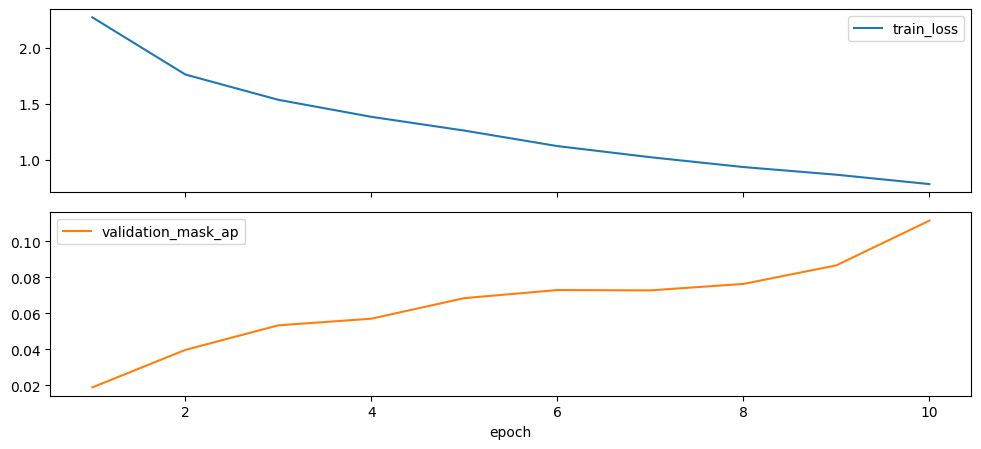

Log: e:\Coding\Python\Computer_Vision\Week_11\results\instance_segmentation\maskrcnn_runs\maskrcnn_scratch\training.csv


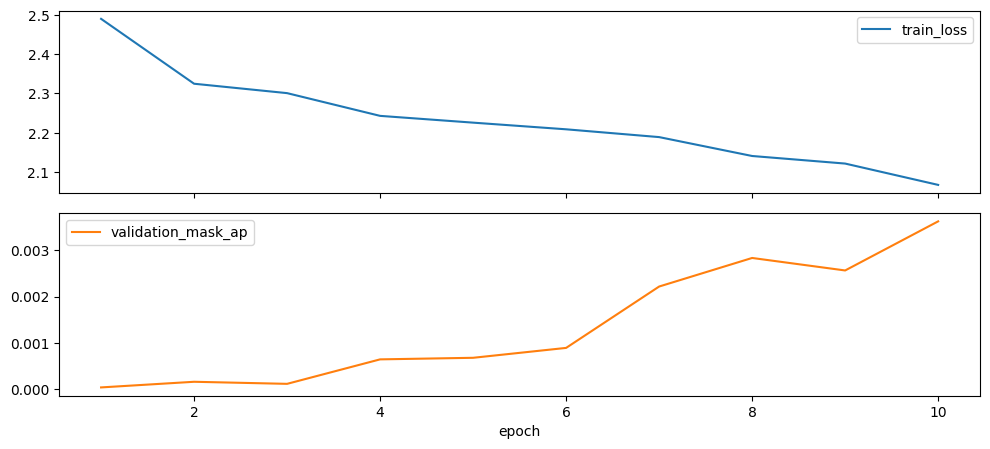

Log: e:\Coding\Python\Computer_Vision\Week_11\results\instance_segmentation\runs\yolo11n_pretrained\results.csv


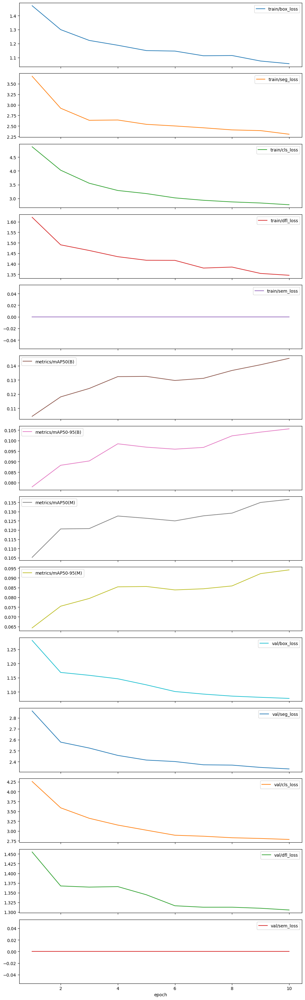

Log: e:\Coding\Python\Computer_Vision\Week_11\results\instance_segmentation\runs\yolo11n_scratch\results.csv


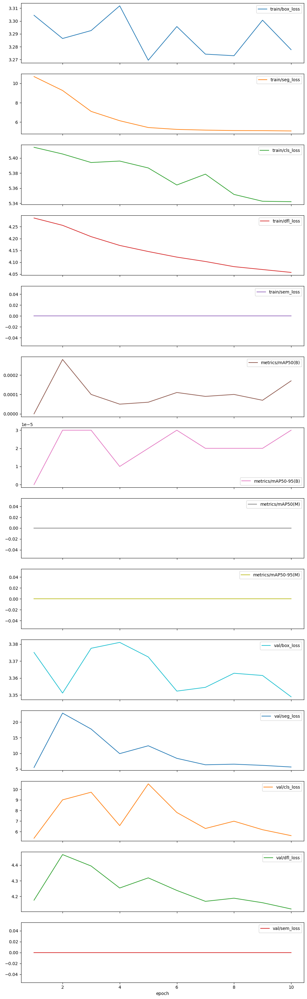

Log: e:\Coding\Python\Computer_Vision\Week_11\results\instance_segmentation\runs\yolov8n_pretrained\results.csv


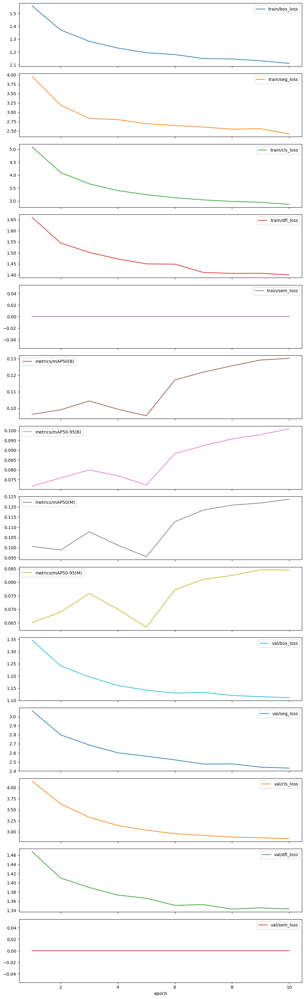

Log: e:\Coding\Python\Computer_Vision\Week_11\results\instance_segmentation\runs\yolov8n_scratch\results.csv


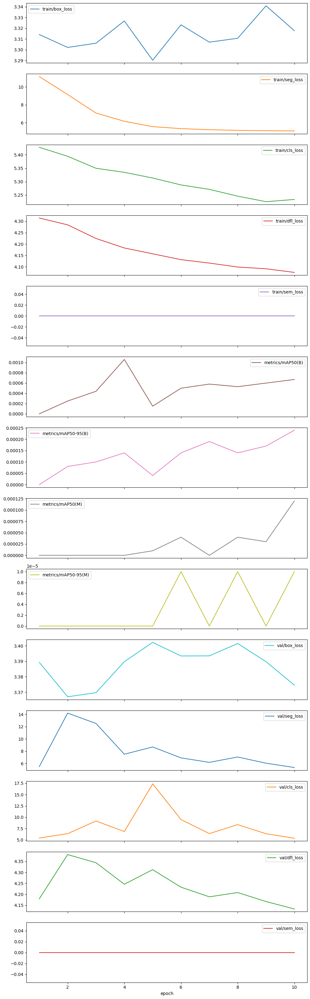

In [19]:
LOG_ROOT_OVERRIDE=None
log_root=Path(LOG_ROOT_OVERRIDE) if LOG_ROOT_OVERRIDE else (EVAL_ROOT.parent if EVAL_ROOT else Path('/kaggle/working/instance_segmentation'))
log_files=[]
if log_root.is_dir():
    log_files=sorted(set(log_root.rglob('results.csv'))|set(log_root.rglob('training.csv')))
for i,f in enumerate(log_files):
    try: log=pd.read_csv(f); log.columns=log.columns.str.strip()
    except Exception as e: print('Log gagal dibaca:',f,e); continue
    if 'epoch' not in log: continue
    print('Log:',f)
    metrics=[c for c in log if ('loss' in c.lower() or 'map' in c.lower() or 'ap'==c.lower() or 'mask_ap' in c.lower()) and pd.api.types.is_numeric_dtype(log[c])]
    if metrics:
        log.set_index('epoch')[metrics].to_csv(OUTPUT_ROOT/f'training_log_{i:02}.csv')
        ax=log.set_index('epoch')[metrics].plot(subplots=True,figsize=(10,max(4,2.3*len(metrics))),legend=True)
        fig=np.asarray(ax).flat[0].figure; finish(fig,f'training_log_{i:02}')
if not log_files: print('Log asli tidak ditemukan. Lampirkan results.csv/training.csv, waktu GPU dan logbook asli secara terpisah.')

In [20]:
print('Direktori keluaran:',OUTPUT_ROOT.resolve())
print('Grafik PNG:',len(list(FIG.glob('*.png'))))
print('Kasus kegagalan:',len(CASE_RECORDS),'/ 5')
print('Eksperimen inisialisasi:', 'tersedia' if WEIGHT_RESULT is not None else 'belum dijalankan / prasyarat belum terpenuhi')
print('Sumber metrik:',SOURCES)
print('AP per kelas:',len(class_table),'baris')
print('Training ulang: tidak ada kode training.')

Direktori keluaran: E:\Coding\Python\Computer_Vision\Week_11\results\analisis_inisialisasi
Grafik PNG: 21
Kasus kegagalan: 5 / 5
Eksperimen inisialisasi: tersedia
Sumber metrik: {'yolov8n_pretrained/original': 'e:\\Coding\\Python\\Computer_Vision\\Week_11\\results\\instance_segmentation\\evaluation\\yolov8n_pretrained\\original\\metrics.json', 'yolov8n_scratch/original': 'viskom-train.ipynb cell 29 stream (snapshot)', 'yolo11n_pretrained/original': 'viskom-train.ipynb cell 29 stream (snapshot)', 'yolo11n_scratch/original': 'viskom-train.ipynb cell 29 stream (snapshot)', 'maskrcnn_pretrained/original': 'viskom-train.ipynb cell 29 stream (snapshot)', 'maskrcnn_scratch/original': 'viskom-train.ipynb cell 29 stream (snapshot)', 'yolov8n_pretrained/all': 'viskom-train.ipynb cell 31 tabel (snapshot AP dibulatkan)', 'yolov8n_pretrained/normal': 'viskom-train.ipynb cell 31 tabel (snapshot AP dibulatkan)', 'yolov8n_pretrained/difficult': 'viskom-train.ipynb cell 31 tabel (snapshot AP dibulatkan

In [21]:
# Arsip hanya hasil analisis; tidak memasukkan model atau dataset.
archive = OUTPUT_ROOT.parent / 'analisis_inisialisasi.zip'
with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUTPUT_ROOT.rglob('*')):
        if p.is_file(): z.write(p, p.relative_to(OUTPUT_ROOT.parent))
print('ZIP hasil analisis:', archive.resolve())


ZIP hasil analisis: E:\Coding\Python\Computer_Vision\Week_11\results\analisis_inisialisasi.zip
